# 03 · Two-stage anchor-based detector: Faster R-CNN

Faster R-CNN (ResNet-50-FPN v2, COCO-pretrained, torchvision) trained under the shared protocol, then two experiments
on parameters specific to the two-stage design: the number of RPN proposals and the RoI sampling ratio.

**Run on Kaggle:** GPU T4, Internet ON. Inputs: competition data + notebook 01 output.
To skip training on a re-run, also attach the output of a previous run of this notebook (weights are reused).

In [1]:
%%writefile vd_utils.py
"""Shared helpers for the VisDrone-VID homework: data loading, COCO evaluation, submission writing."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


def find_data_root(start="/kaggle/input"):
    """Folder that contains train/, val/ and test/ (found by its train/annotations_coco.json)."""
    hits = sorted(Path(start).glob("**/train/annotations_coco.json"))
    if not hits:
        raise FileNotFoundError(f"train/annotations_coco.json not found under {start}: attach the competition data")
    return hits[0].parent.parent


def load_split(root, split):
    """COCO json of one split -> (images, annotations) DataFrames with 0-based `cls` and pixel boxes."""
    root = Path(root)
    coco = json.loads((root / split / "annotations_coco.json").read_text())
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    if "video" in imgs:
        imgs["clip"] = imgs["video"].astype(str)
    else:
        imgs["clip"] = imgs["file_name"].map(lambda f: Path(f).parent.name)
    imgs["path"] = [_image_path(root, split, f) for f in imgs["file_name"]]

    anns = pd.DataFrame(coco["annotations"])
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["iscrowd"] = anns.get("iscrowd", 0)
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id", "clip", "width", "height"]], on="image_id")
    return imgs, anns


def _image_path(root, split, file_name):
    for p in (root / split / file_name, root / split / "images" / file_name, root / file_name):
        if p.exists():
            return str(p)
    raise FileNotFoundError(f"image {file_name} not found in {root / split}")


def coco_eval(gt_json, dets, img_ids=None, cat_ids=None, verbose=False):
    """COCO mAP with ignored regions (iscrowd=1) skipped and up to 500 detections per image.

    dets: list of dicts {image_id, category_id (1-based), bbox [x, y, w, h], score}.
    """
    import contextlib, io
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    quiet = contextlib.redirect_stdout(io.StringIO()) if not verbose else contextlib.nullcontext()
    with quiet:
        gt = COCO(str(gt_json))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, 500]
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        if cat_ids is not None:
            E.params.catIds = list(cat_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    out = {k: float(v) for k, v in zip(["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"], s[:6])}
    # per-class AP[.5:.95] from the same evaluation: precision has shape [IoU, recall, class, area, maxDets]
    prec = E.eval["precision"][:, :, :, 0, -1]
    for k, cat in enumerate(E.params.catIds):
        p = prec[:, :, k]
        out[f"AP_{CLASSES[cat - 1]}"] = float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    return out


def write_submission(dets, test_csv, out_path, max_dets=500):
    """dets: dict image_id (str, e.g. clip_001_0000001) -> array N x 6 [cls, score, x, y, w, h] in pixels."""
    test = pd.read_csv(test_csv)
    rows = []
    for image_id in test["image_id"]:
        d = np.asarray(dets.get(image_id, np.zeros((0, 6))), dtype=float).reshape(-1, 6)
        d = d[np.argsort(-d[:, 1])][:max_dets]
        rows.append(" ".join(f"{int(c)} {s:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}" for c, s, x, y, w, h in d))
    sub = pd.DataFrame({"image_id": test["image_id"], "PredictionString": rows})
    sub.to_csv(out_path, index=False)
    return sub

Writing vd_utils.py


In [2]:
# setup
!pip install -q pycocotools
import os; os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, json, math, random, time
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
import torchvision.transforms.functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import vd_utils as vd

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all()
YOLO_DIR = next(Path("/kaggle/input").glob("**/vd_yolo/data.yaml")).parent    # output of notebook 01
ROOT, WORK = vd.find_data_root(), Path("/kaggle/working")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WEIGHTS = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT                          # COCO-pretrained
val_imgs, _ = vd.load_split(ROOT, "val")
VAL_GT = ROOT / "val" / "annotations_coco.json"
print("device:", DEVICE, "| yolo dataset:", YOLO_DIR)

device: cuda | yolo dataset: /kaggle/input/notebooks/yarema1234/notebook0f34d49e70/vd_yolo


## 1. Data and training protocol
* **train:** the masked frames from notebook 01, every 2nd of them (= every 8th video frame, 3 036 frames).
  Faster R-CNN is ~3× slower per image than YOLO; the IoU table in notebook 01 shows frames 8 apart still overlap by 0.44,
  so this keeps most of the information at half the cost. All experiments in this notebook use exactly the same frames.
* **input size:** shorter side 720, longer side up to 1280 (same scale as YOLO's 1280 input for 16:9 frames)
* **augmentation:** horizontal flip; **optimiser:** SGD, lr 0.01, momentum 0.9, weight decay 1e-4, 300 warm-up iterations, cosine decay, AMP
* **validation:** the 7 val clips, original (unmasked) frames, official COCO evaluation (`vd.coco_eval`);
  a small subset (every 10th val frame) is scored after each epoch for the learning curve

In [3]:
class YoloFrames(torch.utils.data.Dataset):
    # images + YOLO labels written by notebook 01 -> torchvision targets (xyxy pixels, labels 1..8, 0 = background)
    def __init__(self, split, step=1, train=False):
        self.paths = sorted((YOLO_DIR / "images" / split).glob("*.jpg"))[::step]
        self.train = train
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        p = self.paths[i]
        img = TF.to_tensor(Image.open(p).convert("RGB")); H, W = img.shape[1:]
        lab = YOLO_DIR / "labels" / p.parent.name / f"{p.stem}.txt"
        a = np.loadtxt(lab, ndmin=2) if lab.exists() and lab.stat().st_size else np.zeros((0, 5))
        boxes = np.c_[(a[:, 1] - a[:, 3] / 2) * W, (a[:, 2] - a[:, 4] / 2) * H, (a[:, 1] + a[:, 3] / 2) * W, (a[:, 2] + a[:, 4] / 2) * H]
        keep = (boxes[:, 2] - boxes[:, 0] >= 1) & (boxes[:, 3] - boxes[:, 1] >= 1)
        boxes, labels = boxes[keep], a[keep, 0].astype(int) + 1
        if self.train and random.random() < 0.5:                            # horizontal flip
            img = img.flip(-1); boxes = np.c_[W - boxes[:, 2], boxes[:, 1], W - boxes[:, 0], boxes[:, 3]]
        return img, {"boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), "labels": torch.tensor(labels, dtype=torch.int64)}

TRAIN_STEP = 2
train_ds = YoloFrames("train", step=TRAIN_STEP, train=True)
CURVE_PATHS = val_imgs.sort_values("image_id")["path"].tolist()[::10]          # learning-curve subset
CURVE_IDS = val_imgs.sort_values("image_id")["image_id"].tolist()[::10]
print("train frames:", len(train_ds), "| val frames:", len(val_imgs), "| curve subset:", len(CURVE_PATHS))

train frames: 3036 | val frames: 2846 | curve subset: 285


## 2. Model, training and inference helpers

In [4]:
BASE = dict(min_size=720, max_size=1280, epochs=4, batch=4, lr=0.01, warmup=300,
            rpn_pre_train=2000, rpn_post_train=2000, rpn_pre_test=1000, rpn_post_test=1000,
            roi_batch=512, roi_pos=0.25)

def build_model(cfg):
    m = fasterrcnn_resnet50_fpn_v2(
        weights=WEIGHTS, min_size=cfg["min_size"], max_size=cfg["max_size"],
        rpn_pre_nms_top_n_train=cfg["rpn_pre_train"], rpn_post_nms_top_n_train=cfg["rpn_post_train"],
        rpn_pre_nms_top_n_test=cfg["rpn_pre_test"], rpn_post_nms_top_n_test=cfg["rpn_post_test"],
        box_batch_size_per_image=cfg["roi_batch"], box_positive_fraction=cfg["roi_pos"],
        box_detections_per_img=500, box_score_thresh=0.001)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, len(vd.CLASSES) + 1)
    return m.to(DEVICE)

@torch.no_grad()
def predict(model, paths, bs=4):
    # {path: array N x 6 [cls (0-based), score, x, y, w, h]} and pure GPU time in ms per image
    model.eval(); out, gpu = {}, 0.0
    for k in range(0, len(paths), bs):
        ims = [TF.to_tensor(Image.open(p).convert("RGB")).to(DEVICE) for p in paths[k:k + bs]]
        if DEVICE == "cuda": torch.cuda.synchronize()
        t = time.time()
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            res = model(ims)
        if DEVICE == "cuda": torch.cuda.synchronize()
        gpu += time.time() - t
        for p, r in zip(paths[k:k + bs], res):
            b = r["boxes"].float().cpu().numpy()
            out[p] = np.c_[r["labels"].cpu().numpy() - 1, r["scores"].float().cpu().numpy(), b[:, :2], b[:, 2:] - b[:, :2]]
    return out, gpu / len(paths) * 1000

def to_coco(preds, imgs):
    pid = dict(zip(imgs["path"], imgs["image_id"]))
    return [{"image_id": int(pid[p]), "category_id": int(c) + 1, "bbox": [float(x), float(y), float(w), float(h)], "score": float(s)}
            for p, d in preds.items() for c, s, x, y, w, h in d]

def wandb_run(name, cfg):
    # logs to Weights & Biases if the WANDB_API_KEY secret is attached; otherwise training runs without it
    try:
        import wandb
        from kaggle_secrets import UserSecretsClient
        wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
        return wandb.init(project="visdrone-hw2", name=name, config=cfg, reinit=True)
    except Exception as e:
        print("W&B logging off:", type(e).__name__); return None

def train(name, cfg):
    seed_all()
    model = build_model(cfg)
    dl = torch.utils.data.DataLoader(train_ds, batch_size=cfg["batch"], shuffle=True, num_workers=4,
                                     collate_fn=lambda b: tuple(zip(*b)), drop_last=True)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=cfg["lr"], momentum=0.9, weight_decay=1e-4)
    total = cfg["epochs"] * len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda it: min(1, (it + 1) / cfg["warmup"]) * 0.5 * (1 + math.cos(math.pi * it / total)))
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
    run, hist, it, t0 = wandb_run(name, cfg), [], 0, time.time()
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); sums = {}
        for imgs, tgts in dl:
            imgs = [i.to(DEVICE) for i in imgs]; tgts = [{k: v.to(DEVICE) for k, v in t.items()} for t in tgts]
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                losses = model(imgs, tgts)
            loss = sum(losses.values())
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); it += 1
            for k, v in losses.items(): sums[k] = sums.get(k, 0) + v.item() / len(dl)
            if run and it % 50 == 0: run.log({"train/" + k: v.item() for k, v in losses.items()} | {"lr": sched.get_last_lr()[0]}, step=it)
        cp, _ = predict(model, CURVE_PATHS)
        cm = vd.coco_eval(VAL_GT, to_coco(cp, val_imgs), img_ids=CURVE_IDS)
        hist.append({"epoch": ep, **sums, "curve mAP": cm["mAP"], "curve AP50": cm["AP50"], "minutes": (time.time() - t0) / 60})
        print(f"{name} | epoch {ep} | loss {sum(sums.values()):.3f} | subset mAP {cm['mAP']:.3f} | {hist[-1]['minutes']:.0f} min")
        if run: run.log({"val_subset/mAP": cm["mAP"], "val_subset/AP50": cm["AP50"], "epoch": ep}, step=it)
    if run: run.finish()
    return model, pd.DataFrame(hist)

## 3. Experiments
| name | change vs baseline | why |
|---|---|---|
| `frcnn_base` | torchvision defaults (1 000 test proposals, 512 RoIs per image, 25 % positive) | reference |
| `frcnn_rpn3000` | 3 000 proposals per image at train and test | frames hold up to 180 objects; with many small objects 1 000 proposals may not cover all of them |
| `frcnn_roi_pos50` | 256 RoIs per image, 50 % positive | dense frames give many positive RoIs; a higher positive share gives the box head more object examples per step |

In [5]:
EXPS = {
    "frcnn_base": {},
    "frcnn_rpn3000": dict(rpn_pre_train=3000, rpn_post_train=3000, rpn_pre_test=3000, rpn_post_test=3000),
    "frcnn_roi_pos50": dict(roi_batch=256, roi_pos=0.5),
}
(WORK / "frcnn").mkdir(exist_ok=True)
RESULTS, HIST, VAL_PREDS = {}, {}, {}
for name, change in EXPS.items():
    cfg = {**BASE, **change}
    prev = sorted(Path("/kaggle/input").glob(f"**/frcnn/{name}.pt"))
    if prev:                                                                       # reuse a previous run
        model = build_model(cfg); model.load_state_dict(torch.load(prev[0], map_location=DEVICE))
        hp = prev[0].with_name(f"{name}_history.csv")
        HIST[name] = pd.read_csv(hp) if hp.exists() else pd.DataFrame(); train_min = HIST[name]["minutes"].max() if len(HIST[name]) else np.nan
        print("reused", prev[0])
    else:
        model, HIST[name] = train(name, cfg)
        train_min = HIST[name]["minutes"].max()
        torch.save(model.state_dict(), WORK / "frcnn" / f"{name}.pt"); HIST[name].to_csv(WORK / "frcnn" / f"{name}_history.csv", index=False)
    VAL_PREDS[name], ms = predict(model, val_imgs["path"].tolist())
    RESULTS[name] = {**vd.coco_eval(VAL_GT, to_coco(VAL_PREDS[name], val_imgs)), "GPU ms / image": ms, "train min": train_min}
    del model; gc.collect(); torch.cuda.empty_cache()
    pd.DataFrame(RESULTS).T.to_csv(WORK / "results_03.csv")

R = pd.DataFrame(RESULTS).T
display(R[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "GPU ms / image", "train min"]].round(4))
display(R[[f"AP_{c}" for c in vd.CLASSES]].T.round(3))

frcnn_base | epoch 1 | loss 1.024 | subset mAP 0.199 | 10 min
frcnn_base | epoch 2 | loss 0.721 | subset mAP 0.219 | 20 min
frcnn_base | epoch 3 | loss 0.635 | subset mAP 0.226 | 30 min
frcnn_base | epoch 4 | loss 0.587 | subset mAP 0.230 | 39 min
frcnn_rpn3000 | epoch 1 | loss 1.036 | subset mAP 0.211 | 10 min
frcnn_rpn3000 | epoch 2 | loss 0.728 | subset mAP 0.218 | 20 min
frcnn_rpn3000 | epoch 3 | loss 0.641 | subset mAP 0.221 | 31 min
frcnn_rpn3000 | epoch 4 | loss 0.594 | subset mAP 0.227 | 41 min
frcnn_roi_pos50 | epoch 1 | loss 1.587 | subset mAP 0.193 | 9 min
frcnn_roi_pos50 | epoch 2 | loss 1.153 | subset mAP 0.212 | 18 min
frcnn_roi_pos50 | epoch 3 | loss 1.002 | subset mAP 0.211 | 27 min
frcnn_roi_pos50 | epoch 4 | loss 0.914 | subset mAP 0.215 | 36 min


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,GPU ms / image,train min
frcnn_base,0.2245,0.4584,0.1944,0.1046,0.2057,0.4166,65.6364,39.4604
frcnn_rpn3000,0.2237,0.4572,0.1915,0.1127,0.2121,0.4119,110.6970,40.9067
frcnn_roi_pos50,0.2171,0.4428,0.1887,0.1032,0.2068,0.3890,65.6577,35.5508


,frcnn_base,frcnn_rpn3000,frcnn_roi_pos50
AP_person,0.268,0.272,0.268
AP_bicycle,0.241,0.235,0.217
AP_car,0.387,0.404,0.381
AP_van,0.251,0.239,0.245
AP_truck,0.272,0.209,0.251
AP_tricycle,0.219,0.233,0.228
AP_bus,0.041,0.072,0.032
AP_motor,0.118,0.126,0.114


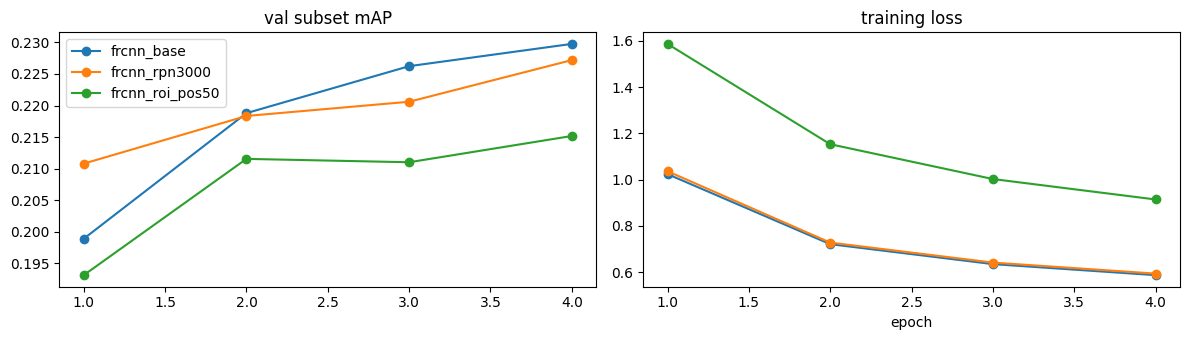

In [6]:
# learning curves on the val subset
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for name, h in HIST.items():
    if len(h):
        ax[0].plot(h.epoch, h["curve mAP"], marker="o", label=name)
        ax[1].plot(h.epoch, h[[c for c in h if c.startswith("loss")]].sum(1), marker="o", label=name)
ax[0].set_title("val subset mAP"); ax[1].set_title("training loss"); ax[0].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(WORK / "frcnn/curves.png", dpi=120); plt.show()

## 4. What each stage contributes
The **RPN** proposes class-agnostic boxes; the **second stage** (RoI head) classifies each proposal and refines its box.
Below: the share of ground-truth objects that at least one proposal covers (IoU ≥ 0.5, *proposal recall*), compared with the
recall of the final detections, by object size. The gap between the two lines is what the second stage loses or adds.

In [7]:
def iou_xywh(a, b):
    ax2, ay2, bx2, by2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2) - np.maximum(a[:, 0, None], b[:, 0]), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2) - np.maximum(a[:, 1, None], b[:, 1]), 0, None)
    inter = iw * ih
    return inter / (a[:, 2, None] * a[:, 3, None] + b[:, 2] * b[:, 3] - inter)

BEST = R["mAP"].astype(float).idxmax(); print("best experiment:", BEST)
best_w = WORK / "frcnn" / f"{BEST}.pt"
if not best_w.exists(): best_w = sorted(Path("/kaggle/input").glob(f"**/frcnn/{BEST}.pt"))[0]
model = build_model({**BASE, **EXPS[BEST]}); model.load_state_dict(torch.load(best_w, map_location=DEVICE)); model.eval()

captured = []
hook = model.roi_heads.register_forward_pre_hook(lambda mod, args: captured.append((args[1], args[2])))
_, gt_anns = vd.load_split(ROOT, "val")
gt_anns = gt_anns[gt_anns.iscrowd == 0]
rows = []
for r in val_imgs.sort_values("image_id").iloc[::10].itertuples():
    captured.clear()
    with torch.no_grad(), torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
        det = model([TF.to_tensor(Image.open(r.path).convert("RGB")).to(DEVICE)])[0]
    props, shapes = captured[0]
    sy, sx = r.height / shapes[0][0], r.width / shapes[0][1]                    # proposals live in the resized image
    p = props[0].float().cpu().numpy() * [sx, sy, sx, sy]
    d = det["boxes"].float().cpu().numpy()[det["scores"].float().cpu().numpy() >= 0.3]
    g = gt_anns[gt_anns.image_id == r.image_id]
    gb = g[["x", "y", "w", "h"]].values
    if not len(gb): continue
    pr = (iou_xywh(gb, np.c_[p[:, :2], p[:, 2:] - p[:, :2]]).max(1) >= 0.5) if len(p) else np.zeros(len(gb), bool)
    dr = (iou_xywh(gb, np.c_[d[:, :2], d[:, 2:] - d[:, :2]]).max(1) >= 0.5) if len(d) else np.zeros(len(gb), bool)
    size = pd.cut(g.w * g.h, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"], right=False)
    rows += [{"size": s, "proposal recall": a, "detection recall (score >= 0.3)": b} for s, a, b in zip(size, pr, dr)]
hook.remove()
stage = pd.DataFrame(rows).groupby("size", observed=True).mean()
stage.loc["all"] = pd.DataFrame(rows)[stage.columns].mean()
display(stage.round(3))

best experiment: frcnn_base


,proposal recall,detection recall (score >= 0.3)
size,,
large,0.991,0.928
medium,0.802,0.697
small,0.641,0.525
all,0.792,0.690


## 5. Failure cases
Detections with score ≥ 0.3 are matched to ground truth (IoU ≥ 0.5, same class). Below: the frames with the most missed objects,
the most false positives, and the most class confusions (a box on a real object but with the wrong class).

totals: {'objects': 114132, 'missed': 43459, 'false pos': 41577, 'wrong class': 12379}


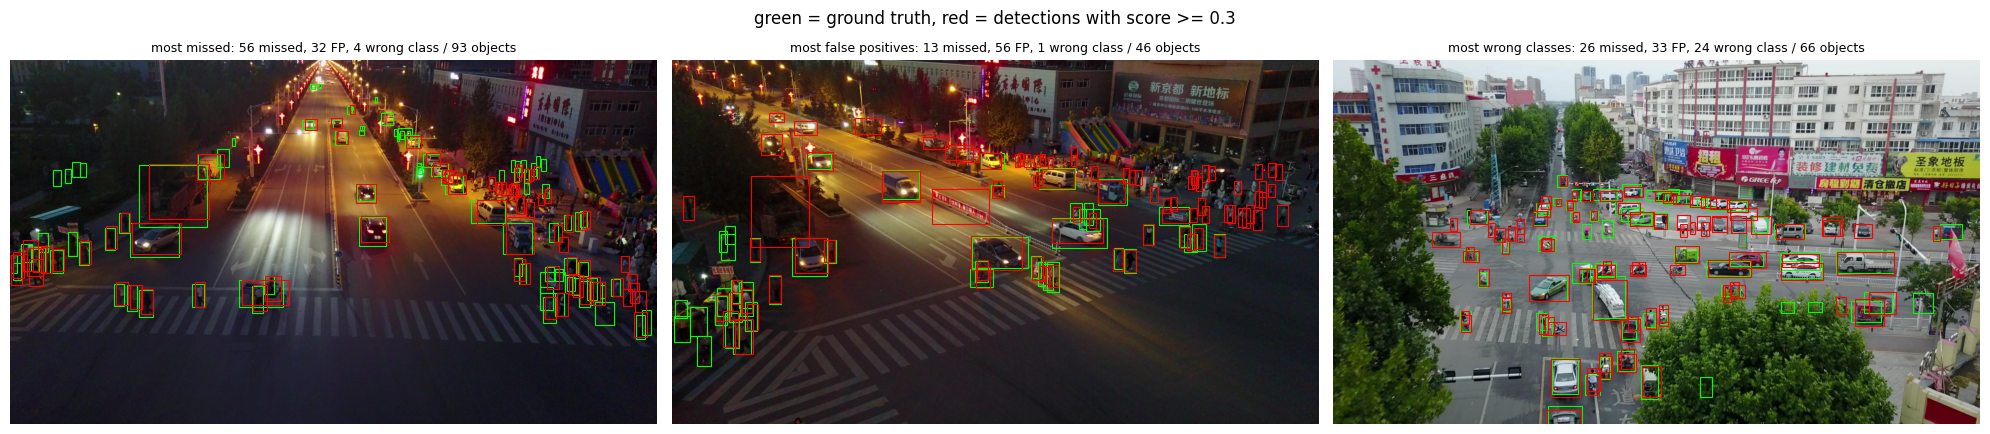

In [8]:
def frame_errors(preds, thr=0.3):
    out = []
    for r in val_imgs.itertuples():
        d = preds.get(r.path, np.zeros((0, 6))); d = d[d[:, 1] >= thr]
        g = gt_anns[gt_anns.image_id == r.image_id]
        gb, gc = g[["x", "y", "w", "h"]].values, g.cls.values
        I = iou_xywh(gb, d[:, 2:]) if len(gb) and len(d) else np.zeros((len(gb), len(d)))
        hit_any = I.max(0) >= 0.5 if len(gb) else np.zeros(len(d), bool)
        same = (I >= 0.5) & (gc[:, None] == d[:, 0][None, :])
        out.append({"image_id": r.image_id, "path": r.path, "objects": len(gb),
                    "missed": int((~same.any(1)).sum()) if len(gb) else 0,
                    "false pos": int((~hit_any).sum()), "wrong class": int((hit_any & ~same.any(0)).sum())})
    return pd.DataFrame(out)

E = frame_errors(VAL_PREDS[BEST])
print("totals:", E[["objects", "missed", "false pos", "wrong class"]].sum().to_dict())

def show(ax, row, preds, thr=0.3):
    ax.imshow(Image.open(row.path)); ax.axis("off")
    for g in gt_anns[gt_anns.image_id == row.image_id].itertuples():
        ax.add_patch(patches.Rectangle((g.x, g.y), g.w, g.h, fill=False, ec="lime", lw=.8))
    for c, s, x, y, w, h in preds[row.path][preds[row.path][:, 1] >= thr]:
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="red", lw=.8))
picks = [E.sort_values("missed").iloc[-1], E.sort_values("false pos").iloc[-1], E.sort_values("wrong class").iloc[-1]]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, row, t in zip(axes, picks, ["most missed", "most false positives", "most wrong classes"]):
    show(ax, row, VAL_PREDS[BEST]); ax.set_title(f"{t}: {row.missed} missed, {row['false pos']} FP, {row['wrong class']} wrong class / {row.objects} objects", fontsize=9)
plt.suptitle("green = ground truth, red = detections with score >= 0.3"); plt.tight_layout()
plt.savefig(WORK / "frcnn/failures.png", dpi=110); plt.show()

## 6. Test submission with the best experiment

In [9]:
test = pd.read_csv(ROOT / "test_images.csv"); test["path"] = [str(ROOT / f) for f in test["file_name"]]
tp, _ = predict(model, test["path"].tolist())
dets = {i: tp.get(p, np.zeros((0, 6))) for i, p in zip(test["image_id"], test["path"])}
vd.write_submission(dets, ROOT / "test_images.csv", WORK / "submission_frcnn.csv")
print("written submission_frcnn.csv with", BEST)

written submission_frcnn.csv with frcnn_base
